In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split

In [4]:
dataset = pd.read_csv('Crop_recommendation.csv')

array([[<Axes: title={'center': 'N'}>, <Axes: title={'center': 'P'}>,
        <Axes: title={'center': 'K'}>],
       [<Axes: title={'center': 'temperature'}>,
        <Axes: title={'center': 'humidity'}>,
        <Axes: title={'center': 'ph'}>],
       [<Axes: title={'center': 'rainfall'}>, <Axes: >, <Axes: >]],
      dtype=object)

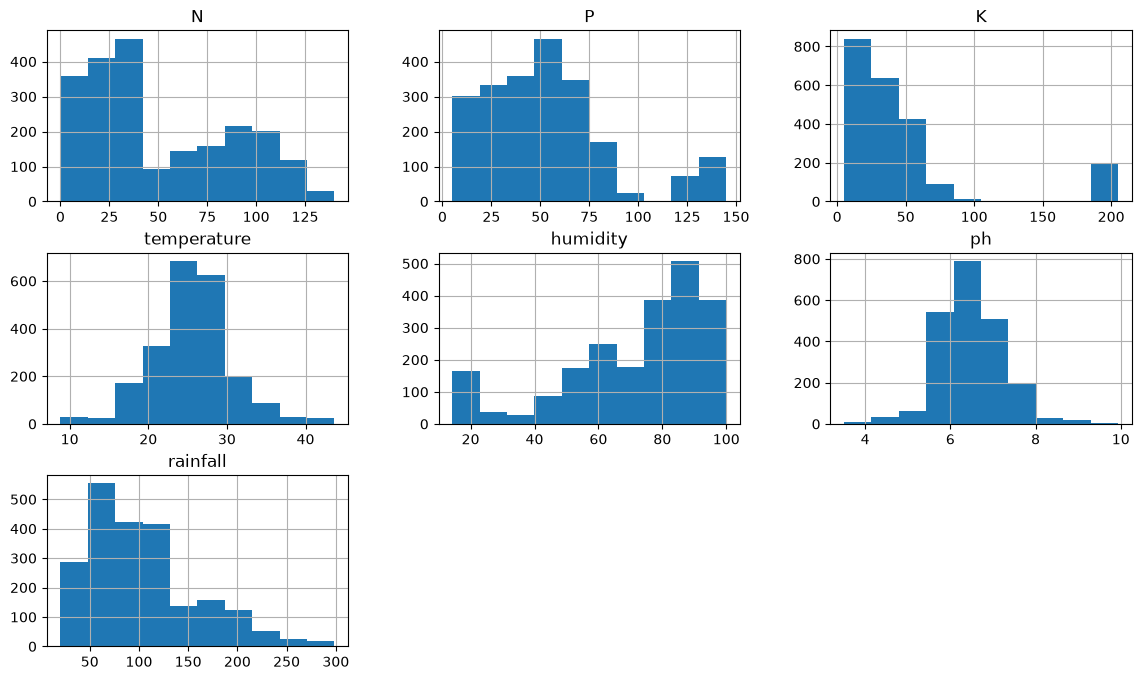

In [7]:
dataset.hist(figsize=(14,8))

<Axes: >

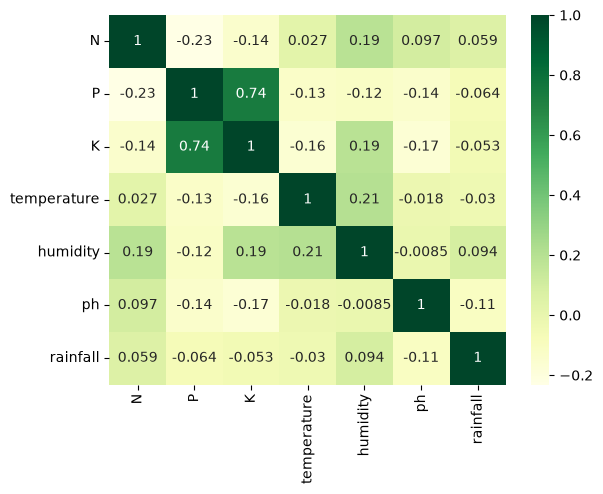

In [9]:
sns.heatmap(dataset.drop('label',axis=1).corr(),annot=True,cmap="YlGn")

/tmp/ipykernel_4091/3272639276.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x="label", y=col, ax=ax, palette="Greens")
/tmp/ipykernel_4091/3272639276.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x="label", y=col, ax=ax, palette="Greens")
/tmp/ipykernel_4091/3272639276.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x="label", y=col, ax=ax, palette="Greens")
/tmp/ipykernel_4091/3272639276.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be remov

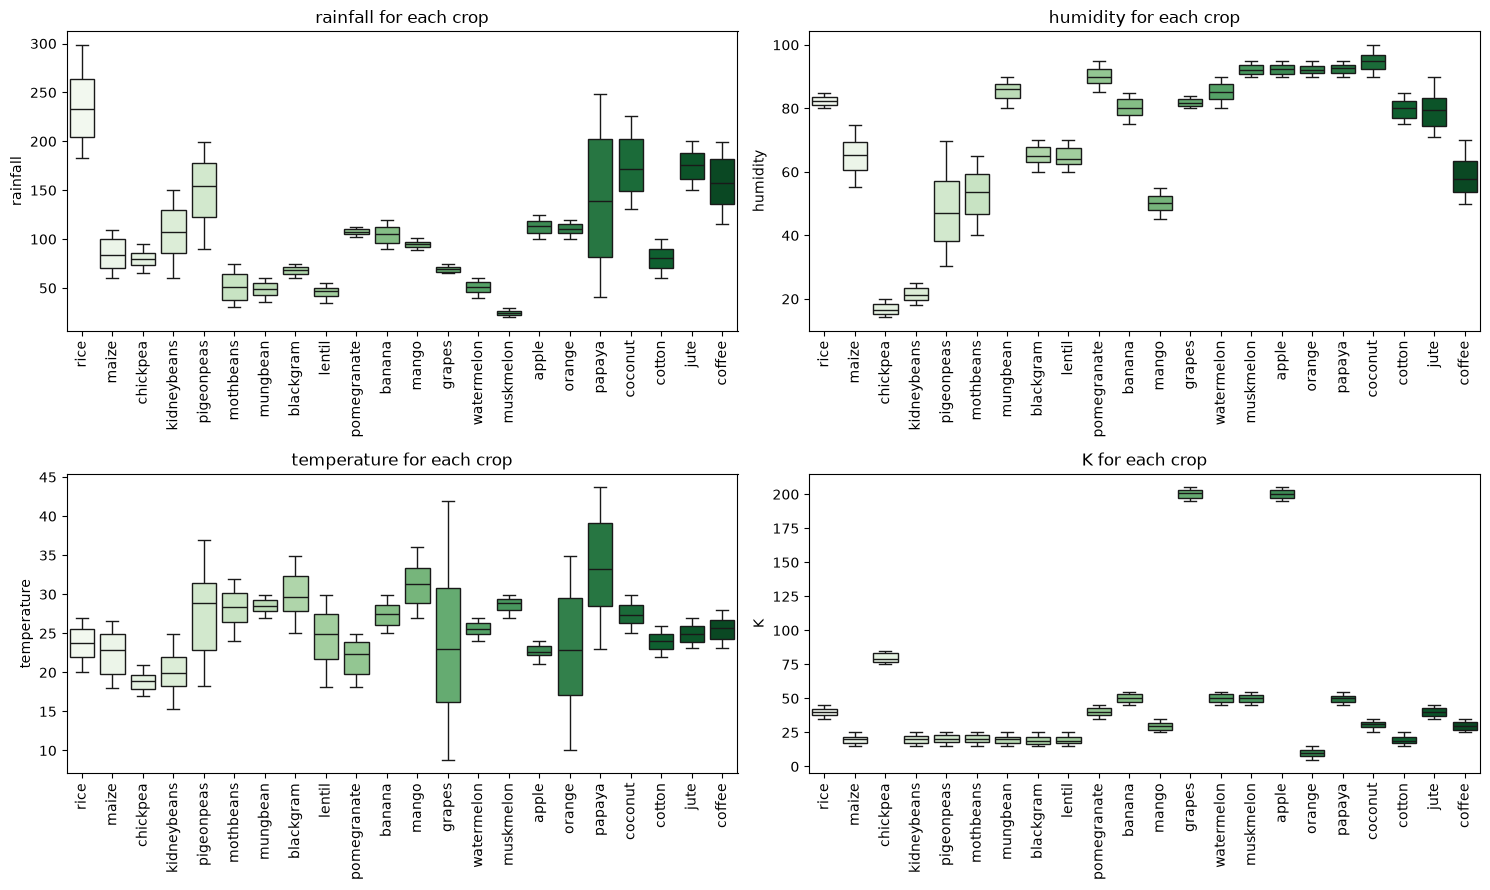

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flatten(), ["rainfall", "humidity", "temperature", "K"]):
    sns.boxplot(data=dataset, x="label", y=col, ax=ax, palette="Greens")
    ax.set_title(col + " for each crop")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

In [27]:

preprocessor = ColumnTransformer([
    ("std", StandardScaler(), ["N", "P", "temperature", "humidity", "ph"]),
    ("robust", RobustScaler(), ["K", "rainfall"]),
])

X_train, X_test, y_train, y_test = train_test_split(
    dataset.drop('label',axis=1)
    ,dataset['label'].astype('category').cat.codes
    ,test_size=.2
    ,random_state=42)



In [28]:
X = preprocessor.fit_transform(X_train)
X_test = preprocessor.fit(X_test)

In [31]:
import pickle
with open("preprocessed_data.pkl",'wb') as f:
    pickle.dump({
        "X_train":X_train,
        "X_test":X_test,
        "y_train":y_train, 
        "y_test":y_test
    },f)